In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    mean_squared_error,
    r2_score
)
print("Libraries imported successfully for Model 2.")

Libraries imported successfully for Model 2.


In [2]:
accepted_file = "accepted.csv"
stage2_cols = [
    "loan_amnt",
    "term",
    "int_rate",
    "installment",
    "grade",
    "emp_title", 
    "emp_length",
    "home_ownership",
    "annual_inc",
    "verification_status",
    "purpose",
    "dti",
    "fico_range_low",
    "open_acc",
    "revol_bal",
    "revol_util",
    "loan_status",
]
df_raw2 = pd.read_csv(accepted_file, usecols=stage2_cols, nrows=30000)
df_model2 = df_raw2[
    df_raw2["loan_status"].isin(["Fully Paid", "Charged Off"])
].copy()
df_model2["repayment_risk"] = np.where(
    df_model2["loan_status"] == "Fully Paid", 0, 1
)
df_model2 = df_model2.drop(columns=["loan_status"])
if len(df_model2) > 20000:
  df_model2 = df_model2.sample(n=20000, random_state=42).reset_index(drop=True)
print("Model 2 Dataset Shape:", df_model2.shape)
df_model2.head()

Model 2 Dataset Shape: (20000, 17)


,loan_amnt,term,int_rate,installment,grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,purpose,dti,fico_range_low,open_acc,revol_bal,revol_util,repayment_risk
0,7875.0,36 months,13.18,266.03,C,Career planner,2 years,RENT,44000.0,Source Verified,debt_consolidation,37.94,695.0,20.0,4024.0,47.9,0
1,12000.0,36 months,10.64,390.83,B,lab assistant,10+ years,RENT,73000.0,Not Verified,debt_consolidation,14.99,725.0,17.0,22344.0,25.1,0
2,20000.0,60 months,11.22,437.05,B,Senior Associate,2 years,MORTGAGE,200000.0,Source Verified,credit_card,10.18,740.0,4.0,32278.0,69.4,0
3,29000.0,60 months,8.49,594.84,B,Service Manager,10+ years,MORTGAGE,101000.0,Verified,debt_consolidation,7.69,715.0,14.0,29310.0,43.0,0
4,10800.0,36 months,7.26,334.76,A,oilfeild tech,8 years,RENT,120000.0,Not Verified,credit_card,25.86,725.0,18.0,10853.0,45.2,1


In [3]:
print(df_model2.shape)
df_model2.info()
print(df_model2['repayment_risk'].value_counts())

(20000, 17)
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   loan_amnt            20000 non-null  float64
 1   term                 20000 non-null  str    
 2   int_rate             20000 non-null  float64
 3   installment          20000 non-null  float64
 4   grade                20000 non-null  str    
 5   emp_title            18726 non-null  str    
 6   emp_length           18730 non-null  str    
 7   home_ownership       20000 non-null  str    
 8   annual_inc           20000 non-null  float64
 9   verification_status  20000 non-null  str    
 10  purpose              20000 non-null  str    
 11  dti                  19999 non-null  float64
 12  fico_range_low       20000 non-null  float64
 13  open_acc             20000 non-null  float64
 14  revol_bal            20000 non-null  float64
 15  revol_util           19989 non-null

In [4]:
df_model2['term'] = df_model2['term'].astype(str).str.replace('months', '').str.strip()
df_model2['term'] = pd.to_numeric(df_model2['term'], errors='coerce')
def clean_emp_length(val):
    if pd.isna(val):
        return np.nan
    val = str(val).strip()
    if '<' in val:
        return 0.5
    if '10+' in val:
        return 10.0
    for word in val.split():
        if word.isdigit():
            return float(word)
    return np.nan
df_model2['emp_length'] = df_model2['emp_length'].apply(clean_emp_length)
print(df_model2.dtypes)

loan_amnt              float64
term                     int64
int_rate               float64
installment            float64
grade                      str
emp_title                  str
emp_length             float64
home_ownership             str
annual_inc             float64
verification_status        str
purpose                    str
dti                    float64
fico_range_low         float64
open_acc               float64
revol_bal              float64
revol_util             float64
repayment_risk           int64
dtype: object


In [5]:
import re


# 3.1B Clean and Categorize Occupation / Designation (emp_title)
def categorize_occupation(title):
  """Map raw emp_title strings into 8 standardized occupation categories."""
  if pd.isna(title):
    return "Other"

  cleaned = re.sub(r"\s+", " ", str(title).lower().strip())
  if not cleaned:
    return "Other"

  def matches_any(keywords):
    pattern = (
        r"\b(?:" + "|".join(re.escape(k.strip()) for k in keywords) + r")\b"
    )
    return re.search(pattern, cleaned) is not None

  if matches_any([
      "manager",
      "director",
      "vp",
      "president",
      "chief",
      "exec",
      "supervisor",
      "lead",
      "head",
  ]):
    return "Management"
  elif matches_any([
      "nurse",
      "rn",
      "doctor",
      "physician",
      "medic",
      "health",
      "therapist",
      "pharmacist",
      "dental",
  ]):
    return "Healthcare"
  elif matches_any([
      "engineer",
      "developer",
      "software",
      "it",
      "tech",
      "programmer",
      "analyst",
      "architect",
      "data",
  ]):
    return "Tech_Engineering"
  elif matches_any([
      "teacher",
      "professor",
      "educator",
      "school",
      "instructor",
      "principal",
      "faculty",
  ]):
    return "Education"
  elif matches_any([
      "accountant",
      "finance",
      "bank",
      "sales",
      "broker",
      "consultant",
      "advisor",
      "auditor",
      "marketing",
  ]):
    return "Finance_Sales"
  elif matches_any([
      "owner",
      "self",
      "founder",
      "ceo",
      "partner",
      "entrepreneur",
      "contractor",
  ]):
    return "Owner_SelfEmployed"
  elif matches_any([
      "driver",
      "mechanic",
      "technician",
      "operator",
      "warehouse",
      "clerk",
      "assistant",
      "admin",
      "officer",
  ]):
    return "Operations_Admin"
  else:
    return "Other"


if "emp_title" in df_model2.columns:
  df_model2["occupation_category"] = df_model2["emp_title"].apply(
      categorize_occupation
  )
  df_model2 = df_model2.drop(columns=["emp_title"])
elif "occupation_category" not in df_model2.columns:
  raise KeyError(
      "'emp_title' is missing from df_model2; re-run Cell [2] and Cell [4]."
  )

print("Occupation Category Distribution:")
print(df_model2["occupation_category"].value_counts())

Occupation Category Distribution:
occupation_category
Other                 7801
Management            5101
Operations_Admin      2287
Tech_Engineering      1598
Finance_Sales         1003
Healthcare             899
Education              853
Owner_SelfEmployed     458
Name: count, dtype: int64


In [6]:
print(df_model2.isnull().sum())
num_cols_m2 = [
    'loan_amnt', 'term', 'int_rate', 'installment', 'emp_length',
    'annual_inc', 'dti', 'fico_range_low', 'open_acc', 'revol_bal', 'revol_util']
for col in num_cols_m2:
    df_model2[col] = df_model2[col].fillna(df_model2[col].median())
cat_cols_m2 = ['grade', 'home_ownership', 'verification_status', 'purpose']
for col in cat_cols_m2:
    df_model2[col] = df_model2[col].fillna(df_model2[col].mode()[0])
print(df_model2.isnull().sum())
print(df_model2.duplicated().sum())
df_model2 = df_model2.drop_duplicates().reset_index(drop=True)
df_model2['annual_inc'] = df_model2['annual_inc'].clip(upper=df_model2['annual_inc'].quantile(0.99))
df_model2['dti'] = df_model2['dti'].clip(lower=0, upper=df_model2['dti'].quantile(0.99))
df_model2['revol_bal'] = df_model2['revol_bal'].clip(upper=df_model2['revol_bal'].quantile(0.99))
df_model2['revol_util'] = df_model2['revol_util'].clip(lower=0, upper=100)
print("Cleaned Model 2 Shape:", df_model2.shape)

loan_amnt                 0
term                      0
int_rate                  0
installment               0
grade                     0
emp_length             1270
home_ownership            0
annual_inc                0
verification_status       0
purpose                   0
dti                       1
fico_range_low            0
open_acc                  0
revol_bal                 0
revol_util               11
repayment_risk            0
occupation_category       0
dtype: int64
loan_amnt              0
term                   0
int_rate               0
installment            0
grade                  0
emp_length             0
home_ownership         0
annual_inc             0
verification_status    0
purpose                0
dti                    0
fico_range_low         0
open_acc               0
revol_bal              0
revol_util             0
repayment_risk         0
occupation_category    0
dtype: int64
0
Cleaned Model 2 Shape: (20000, 17)


C:\Users\GOUTHAM\AppData\Local\Temp\ipykernel_29476\180344084.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='repayment_risk', data=df_model2, palette='coolwarm')
C:\Users\GOUTHAM\AppData\Local\Temp\ipykernel_29476\180344084.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='grade', y='repayment_risk', data=df_model2, order=grade_order, palette='viridis', errorbar=None)
C:\Users\GOUTHAM\AppData\Local\Temp\ipykernel_29476\180344084.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='home_ownership', y='repayment_risk', data=d

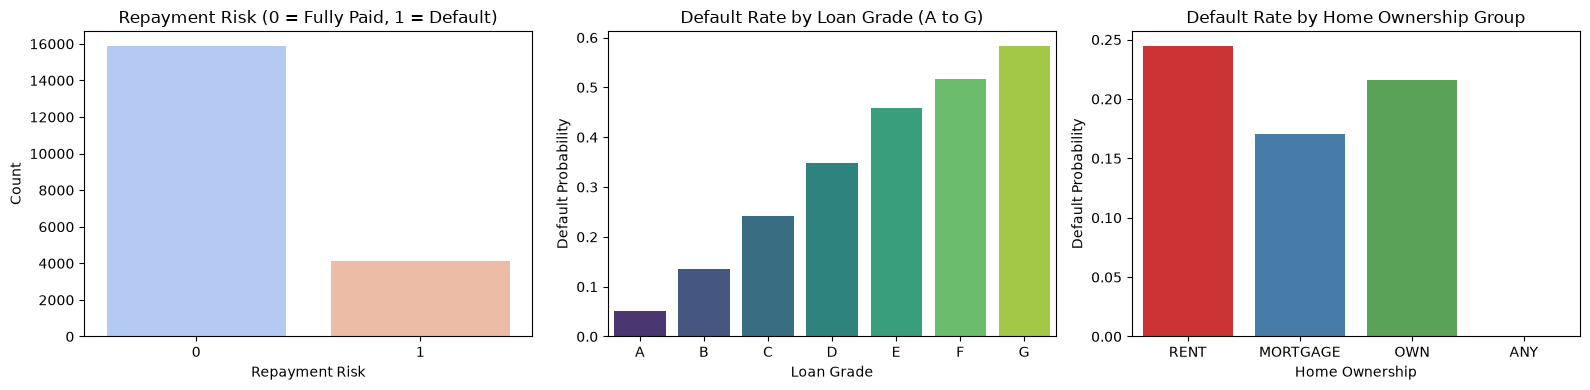

In [7]:
plt.figure(figsize=(16, 4))
plt.subplot(1, 3, 1)
sns.countplot(x='repayment_risk', data=df_model2, palette='coolwarm')
plt.title('Repayment Risk (0 = Fully Paid, 1 = Default)')
plt.xlabel('Repayment Risk')
plt.ylabel('Count')
plt.subplot(1, 3, 2)
grade_order = sorted(df_model2['grade'].unique())
sns.barplot(x='grade', y='repayment_risk', data=df_model2, order=grade_order, palette='viridis', errorbar=None)
plt.title('Default Rate by Loan Grade (A to G)')
plt.xlabel('Loan Grade')
plt.ylabel('Default Probability')
plt.subplot(1, 3, 3)
sns.barplot(x='home_ownership', y='repayment_risk', data=df_model2, palette='Set1', errorbar=None)
plt.title('Default Rate by Home Ownership Group')
plt.xlabel('Home Ownership')
plt.ylabel('Default Probability')
plt.tight_layout()
plt.show()

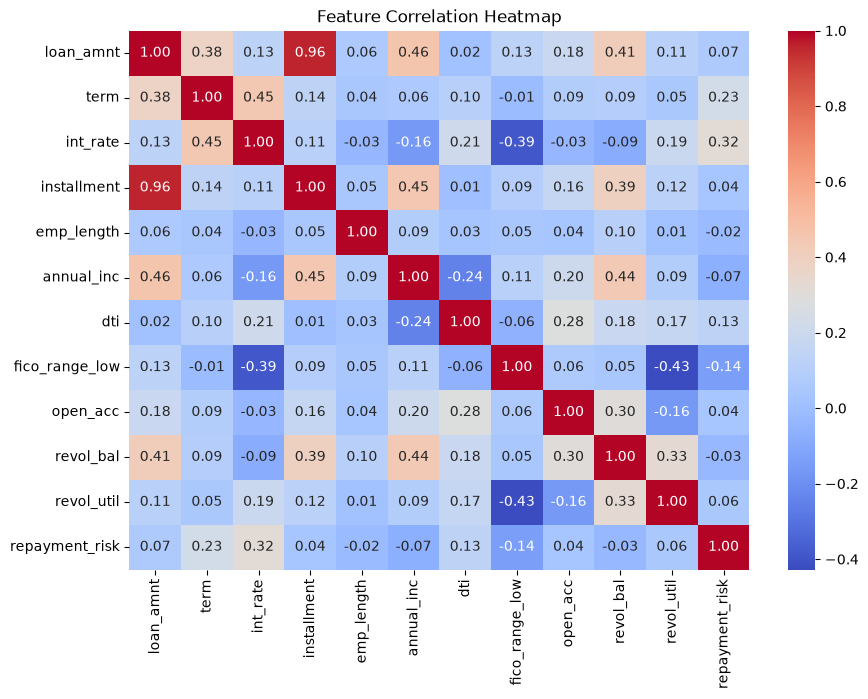

In [8]:
plt.figure(figsize=(10, 7))
corr_m2 = df_model2.corr(numeric_only=True)
sns.heatmap(corr_m2, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.show()

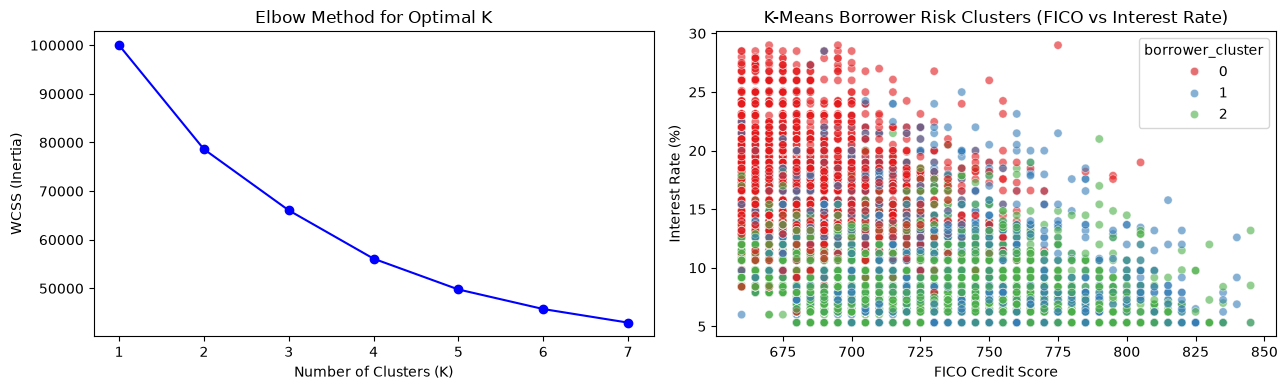

                  loan_amnt  int_rate  annual_inc    dti  fico_range_low  \
borrower_cluster                                                           
0                  13356.67     15.41    56502.43  25.87          680.70   
1                  24843.15     11.02   129267.62  16.38          707.41   
2                   9669.32      9.82    63872.81  15.21          699.52   

                  repayment_risk  
borrower_cluster                  
0                           0.33  
1                           0.16  
2                           0.13  


In [9]:
cluster_features = ['loan_amnt', 'int_rate', 'annual_inc', 'dti', 'fico_range_low']
X_cluster = df_model2[cluster_features].copy()
scaler_kmeans = StandardScaler()
X_cluster_scaled = scaler_kmeans.fit_transform(X_cluster)
wcss = []
for k in range(1, 8):
    km = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    km.fit(X_cluster_scaled)
    wcss.append(km.inertia_)
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10)
df_model2['borrower_cluster'] = kmeans.fit_predict(X_cluster_scaled)
plt.figure(figsize=(13, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, 8), wcss, marker='o', color='blue')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.subplot(1, 2, 2)
sns.scatterplot(
    x=df_model2['fico_range_low'],
    y=df_model2['int_rate'],
    hue=df_model2['borrower_cluster'],
    palette='Set1',
    alpha=0.6
)
plt.title('K-Means Borrower Risk Clusters (FICO vs Interest Rate)')
plt.xlabel('FICO Credit Score')
plt.ylabel('Interest Rate (%)')
plt.tight_layout()
plt.show()
print(df_model2.groupby('borrower_cluster')[cluster_features + ['repayment_risk']].mean().round(2))

In [10]:
df_model2["loan_to_income"] = df_model2["loan_amnt"] / (
    df_model2["annual_inc"] + 1
)
df_model2["installment_to_monthly_inc"] = df_model2["installment"] / (
    (df_model2["annual_inc"] / 12.0) + 1
)

cols_to_drop = ["repayment_risk"]
if "borrower_cluster" in df_model2.columns:
  cols_to_drop.append("borrower_cluster")

X_m2 = df_model2.drop(columns=cols_to_drop)
y_m2 = df_model2["repayment_risk"]

applicant_groups_df = df_model2[[
    "home_ownership",
    "grade",
    "occupation_category",
    "annual_inc",
    "loan_amnt",
    "int_rate",
]].copy()

X_m2 = pd.get_dummies(
    X_m2,
    columns=[
        "grade",
        "home_ownership",
        "verification_status",
        "purpose",
        "occupation_category",
    ],
    drop_first=True,
)
X_m2.head()

,loan_amnt,term,int_rate,installment,emp_length,annual_inc,dti,fico_range_low,open_acc,revol_bal,...,purpose_renewable_energy,purpose_small_business,purpose_vacation,occupation_category_Finance_Sales,occupation_category_Healthcare,occupation_category_Management,occupation_category_Operations_Admin,occupation_category_Other,occupation_category_Owner_SelfEmployed,occupation_category_Tech_Engineering
0,7875.0,36,13.18,266.03,2.0,44000.0,37.94,695.0,20.0,4024.0,...,False,False,False,False,False,False,False,True,False,False
1,12000.0,36,10.64,390.83,10.0,73000.0,14.99,725.0,17.0,22344.0,...,False,False,False,False,False,False,True,False,False,False
2,20000.0,60,11.22,437.05,2.0,200000.0,10.18,740.0,4.0,32278.0,...,False,False,False,False,False,False,False,True,False,False
3,29000.0,60,8.49,594.84,10.0,101000.0,7.69,715.0,14.0,29310.0,...,False,False,False,False,False,True,False,False,False,False
4,10800.0,36,7.26,334.76,8.0,120000.0,25.86,725.0,18.0,10853.0,...,False,False,False,False,False,False,False,False,False,True


In [11]:
X_train_m2, X_test_m2, y_train_m2, y_test_m2 = train_test_split(
    X_m2,
    y_m2,
    test_size=0.20,
    random_state=42,
    stratify=y_m2
)
groups_test_m2 = applicant_groups_df.loc[X_test_m2.index].copy()
print("Training data:", X_train_m2.shape)
print("Testing data :", X_test_m2.shape)
scaler_m2 = StandardScaler()
X_train_m2_scaled = scaler_m2.fit_transform(X_train_m2)
X_test_m2_scaled = scaler_m2.transform(X_test_m2)
from imblearn.over_sampling import SMOTE
print(y_train_m2.value_counts())
smote = SMOTE(random_state=42)
X_train_m2_balanced, y_train_m2_balanced = smote.fit_resample(
    X_train_m2_scaled,
    y_train_m2
)
print(y_train_m2_balanced.value_counts())

Training data: (16000, 42)
Testing data : (4000, 42)
repayment_risk
0    12711
1     3289
Name: count, dtype: int64
repayment_risk
0    12711
1    12711
Name: count, dtype: int64


Total original encoded features: 42
Number of components required for 95% variance: 31
Variance retained: 95.06 %


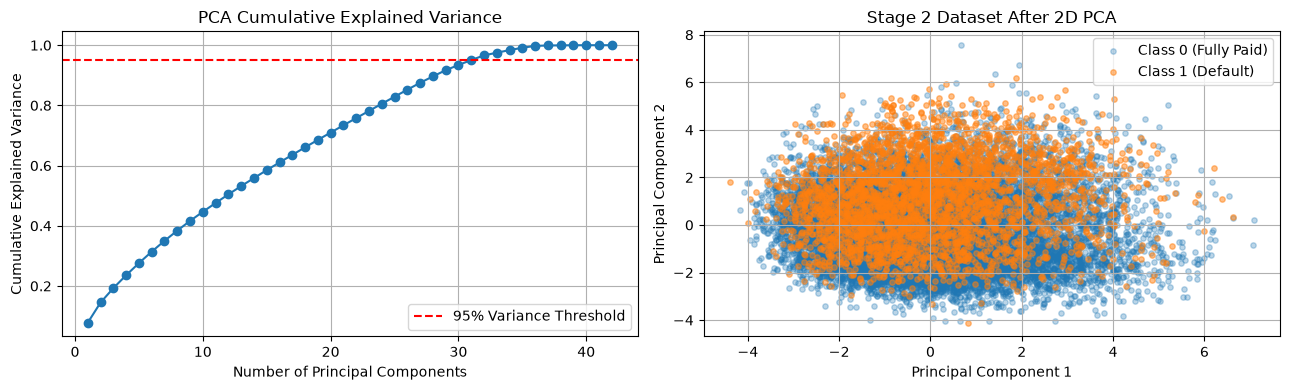

In [12]:
pca_full = PCA()
X_train_pca_full = pca_full.fit_transform(X_train_m2_scaled)
explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)
n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1
print("Total original encoded features:", X_train_m2_scaled.shape[1])
print("Number of components required for 95% variance:", n_components_95)
print("Variance retained:", round(cumulative_variance[n_components_95 - 1] * 100, 2), "%")
pca_95 = PCA(n_components=n_components_95, random_state=42)
X_train_m2_pca = pca_95.fit_transform(X_train_m2_scaled)
X_test_m2_pca = pca_95.transform(X_test_m2_scaled)
plt.figure(figsize=(13, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o')
plt.axhline(y=0.95, color='r', linestyle='--', label='95% Variance Threshold')
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")
plt.legend()
plt.grid(True)
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_train_m2_scaled)
plt.subplot(1, 2, 2)
plt.scatter(X_pca_2d[y_train_m2 == 0, 0], X_pca_2d[y_train_m2 == 0, 1], label='Class 0 (Fully Paid)', alpha=0.3, s=15)
plt.scatter(X_pca_2d[y_train_m2 == 1, 0], X_pca_2d[y_train_m2 == 1, 1], label='Class 1 (Default)', alpha=0.5, s=15)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Stage 2 Dataset After 2D PCA")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [13]:
log_reg_l2_m2 = LogisticRegression(penalty='l2', C=1.0, max_iter=1000, random_state=42)
log_reg_l1_m2 = LogisticRegression(penalty='l1', solver='liblinear', C=1.0, max_iter=1000, random_state=42)
knn_m2 = KNeighborsClassifier(n_neighbors=5)
nb_baseline_m2 = GaussianNB()
nb_smote_m2 = GaussianNB()
svm_linear_m2 = SVC(kernel='linear', C=1, probability=True, random_state=42)
svm_poly_m2 = SVC(kernel='poly', degree=3, C=1, gamma='scale', probability=True, random_state=42)
svm_rbf_m2 = SVC(kernel='rbf', C=1, gamma='scale', probability=True, random_state=42)
dt_m2 = DecisionTreeClassifier(criterion='gini', random_state=42)
rf_m2 = RandomForestClassifier(n_estimators=100, random_state=42)

In [14]:
from sklearn.pipeline import Pipeline
X_reg = df_model2[['fico_range_low']].values
y_reg = df_model2['int_rate'].values
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)
lin_reg_model = LinearRegression()
poly_features = PolynomialFeatures(degree=6)
poly_reg_model = LinearRegression()
ridge_model = Pipeline([
    ('poly', PolynomialFeatures(degree=6)),
    ('scaler', StandardScaler()),
    ('ridge', Ridge(alpha=1.0))
])
lasso_model = Pipeline([
    ('poly', PolynomialFeatures(degree=6)),
    ('scaler', StandardScaler()),
    ('lasso', Lasso(alpha=0.05, max_iter=10000))
])

In [15]:
lin_reg_model.fit(X_reg_train, y_reg_train)
X_reg_train_poly = poly_features.fit_transform(X_reg_train)
poly_reg_model.fit(X_reg_train_poly, y_reg_train)
ridge_model.fit(X_reg_train, y_reg_train)
lasso_model.fit(X_reg_train, y_reg_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('poly', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",6
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",True
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'
Name,Type,Value


In [16]:
lin_reg_model.fit(X_reg_train, y_reg_train)
X_reg_train_poly = poly_features.fit_transform(X_reg_train)
poly_reg_model.fit(X_reg_train_poly, y_reg_train)
ridge_model.fit(X_reg_train, y_reg_train)
lasso_model.fit(X_reg_train, y_reg_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('poly', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",6
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",True
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'
Name,Type,Value


In [17]:
rf_m2.fit(X_train_m2_balanced, y_train_m2_balanced)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

Accuracy: 0.76475
Precision: 0.4115898959881129
Recall: 0.33698296836982966
F1 Score: 0.3705685618729097

Classification Report:               precision    recall  f1-score   support

           0       0.84      0.88      0.86      3178
           1       0.41      0.34      0.37       822

    accuracy                           0.76      4000
   macro avg       0.62      0.61      0.61      4000
weighted avg       0.75      0.76      0.76      4000

                Total_Applicants  Default_Rate_Actual  Default_Rate_Predicted  \
home_ownership                                                                  
MORTGAGE                  1906.0               0.1700                  0.1285   
OWN                        494.0               0.2368                  0.1478   
RENT                      1600.0               0.2381                  0.2219   

                Error_Rate  
home_ownership              
MORTGAGE            0.2009  
OWN                 0.2470  
RENT                0.

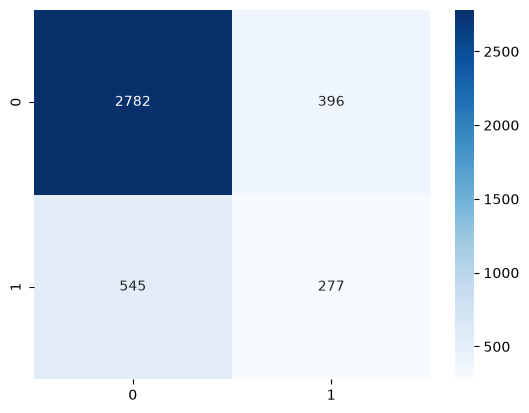

In [18]:
y_pred_m2 = rf_m2.predict(X_test_m2_scaled)
y_proba_m2 = rf_m2.predict_proba(X_test_m2_scaled)[:, 1]
print("Accuracy:", accuracy_score(y_test_m2, y_pred_m2))
print("Precision:", precision_score(y_test_m2, y_pred_m2))
print("Recall:", recall_score(y_test_m2, y_pred_m2))
print("F1 Score:", f1_score(y_test_m2, y_pred_m2))
print("\nClassification Report:", classification_report(y_test_m2, y_pred_m2))
cm_m2 = confusion_matrix(y_test_m2, y_pred_m2)
sns.heatmap(cm_m2, annot=True, fmt='d', cmap='Blues')
groups_test_m2['actual_risk'] = y_test_m2.values
groups_test_m2['predicted_risk'] = y_pred_m2
subgroup_summary = groups_test_m2.groupby('home_ownership').apply(
    lambda g: pd.Series({
        'Total_Applicants': len(g),
        'Default_Rate_Actual': g['actual_risk'].mean().round(4),
        'Default_Rate_Predicted': g['predicted_risk'].mean().round(4),
        'Error_Rate': (g['actual_risk'] != g['predicted_risk']).mean().round(4)
    })
)
print(subgroup_summary)

In [19]:
from sklearn.model_selection import GridSearchCV
param_grid_knn = {
    'n_neighbors': [3, 5, 7, 11, 15],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

grid_search_knn = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid_knn,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
grid_search_knn.fit(X_train_m2_balanced, y_train_m2_balanced)
print("Best KNN Parameters:", grid_search_knn.best_params_)
print("Best CV F1-Score:", round(grid_search_knn.best_score_, 4))
best_knn_model = grid_search_knn.best_estimator_
y_pred_knn_tuned = best_knn_model.predict(X_test_m2_scaled)
print("\nTuned KNN Test Accuracy:", accuracy_score(y_test_m2, y_pred_knn_tuned))
print("Classification Report:\n", classification_report(y_test_m2, y_pred_knn_tuned))

Best KNN Parameters: {'metric': 'manhattan', 'n_neighbors': 3, 'weights': 'distance'}
Best CV F1-Score: 0.8517

Tuned KNN Test Accuracy: 0.66725
Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.71      0.77      3178
           1       0.31      0.50      0.38       822

    accuracy                           0.67      4000
   macro avg       0.58      0.61      0.58      4000
weighted avg       0.74      0.67      0.69      4000



In [20]:
from sklearn.model_selection import RandomizedSearchCV
param_dist_rf = {
    'n_estimators': [50, 100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
random_search_rf = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=param_dist_rf,
    n_iter=10,
    cv=5,
    scoring='f1',
    random_state=42,
    n_jobs=-1
)
random_search_rf.fit(X_train_m2_balanced, y_train_m2_balanced)
print("Best Random Forest Parameters:", random_search_rf.best_params_)
print("Best CV F1-Score:", round(random_search_rf.best_score_, 4))
best_rf_m2 = random_search_rf.best_estimator_
y_pred_rf_tuned = best_rf_m2.predict(X_test_m2_scaled)
print("\nTuned Random Forest Test Accuracy:", accuracy_score(y_test_m2, y_pred_rf_tuned))
print("Classification Report:\n", classification_report(y_test_m2, y_pred_rf_tuned))

Best Random Forest Parameters: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': None}
Best CV F1-Score: 0.8354

Tuned Random Forest Test Accuracy: 0.7715
Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.88      0.86      3178
           1       0.43      0.36      0.39       822

    accuracy                           0.77      4000
   macro avg       0.64      0.62      0.62      4000
weighted avg       0.76      0.77      0.76      4000



In [24]:
import os
import joblib
from sklearn.exceptions import NotFittedError
from sklearn.metrics import accuracy_score, f1_score
from sklearn.utils.validation import check_is_fitted

# Candidate Stage 2 models
candidates_m2 = {
    "Logistic_Regression_L2": log_reg_l2_m2,
    "Random_Forest_Tuned": best_rf_m2 if "best_rf_m2" in locals() else rf_m2,
    "KNN_Tuned": best_knn_model if "best_knn_model" in locals() else knn_m2,
    "Decision_Tree": dt_m2,
    "Naive_Bayes_SMOTE": nb_smote_m2,
}

# Ensure EVERY candidate model is fitted consistently on SMOTE-balanced training data
for name, model in candidates_m2.items():
    try:
        check_is_fitted(model)
    except NotFittedError:
        print(f"Refitting unfitted Stage 2 model on SMOTE data: {name}...")
        model.fit(X_train_m2_balanced, y_train_m2_balanced)

# Also verify the Ridge pricing model is fitted before saving
try:
    check_is_fitted(ridge_model)
except NotFittedError:
    print("Refitting unfitted Ridge pricing model...")
    ridge_model.fit(X_reg_train, y_reg_train)

best_name_m2 = None
best_score_m2 = -1.0
active_model_m2 = None

# Evaluate all candidates and select the single best model supporting predict_proba
for name, model in candidates_m2.items():
    preds = model.predict(X_test_m2_scaled)
    score = f1_score(y_test_m2, preds)
    acc = accuracy_score(y_test_m2, preds)
    has_proba = hasattr(model, "predict_proba")
    print(f"{name:25s} -> Test F1-Score: {score:.4f} | Accuracy: {acc:.4f} | Proba: {has_proba}")

    if has_proba and score > best_score_m2:
        best_score_m2 = score
        best_name_m2 = name
        active_model_m2 = model

if active_model_m2 is None:
    raise RuntimeError("No Stage 2 model supports predict_proba(). Check model configurations.")

print(f"\n>>> WINNING STAGE 2 MODEL SELECTED: {best_name_m2} (F1 = {best_score_m2:.4f})")

# Save winning model and Stage 2 artifacts
desktop_path = os.path.join(os.path.expanduser("~"), "Desktop")
models_dir = os.path.join(desktop_path, "project", "models")
os.makedirs(models_dir, exist_ok=True)

joblib.dump(active_model_m2, os.path.join(models_dir, "stage2_repayment_model.joblib"))
joblib.dump(scaler_m2, os.path.join(models_dir, "stage2_scaler.joblib"))
joblib.dump(list(X_train_m2.columns), os.path.join(models_dir, "stage2_features.joblib"))
joblib.dump(
    {
        "X_test_scaled": X_test_m2_scaled,
        "y_test": y_test_m2.values,
        "groups": groups_test_m2,
    },
    os.path.join(models_dir, "stage2_test_data.joblib"),
)
joblib.dump(ridge_model, os.path.join(models_dir, "stage2_pricing_ridge_model.joblib"))

print(f"Stage 2 Artifacts saved successfully to: {models_dir}")

Logistic_Regression_L2    -> Test F1-Score: 0.2306 | Accuracy: 0.8015 | Proba: True
Random_Forest_Tuned       -> Test F1-Score: 0.3899 | Accuracy: 0.7715 | Proba: True
KNN_Tuned                 -> Test F1-Score: 0.3829 | Accuracy: 0.6673 | Proba: True
Decision_Tree             -> Test F1-Score: 0.2989 | Accuracy: 0.6997 | Proba: True
Naive_Bayes_SMOTE         -> Test F1-Score: 0.3468 | Accuracy: 0.2457 | Proba: True

>>> WINNING STAGE 2 MODEL SELECTED: Random_Forest_Tuned (F1 = 0.3899)
Stage 2 Artifacts saved successfully to: C:\Users\GOUTHAM\Desktop\project\models
